# File Handling and Exception Handling Lab
### Working with Text Files Safely

So far, every value in our programs disappeared as soon as the program stopped, and one typing mistake by the user could crash everything. This lab solves both problems:
- **Files** let a program save data permanently and read it back later: notes, logs, marks, settings, bills.
- **Exception handling** lets a program catch problems, react sensibly and keep going.

This lab works only with **text files** (`.txt`).

| Section | Parts | What you will learn |
|---|---|---|
| **A: File Handling** | 1 to 10 | file paths, opening and closing, modes, writing, reading, `with`, appending, the file pointer, the `os` module, processing text |
| **B: Exception Handling** | 11 to 21 | kinds of errors, tracebacks, built-in exceptions, `try-except`, `else`, `finally`, propagation, `raise`, custom exceptions, errors with files and input, `assert` |
| **C: Putting It All Together** | 22 to 25 | recap, 20 exercises, two real-world projects |

**How to use this lab**
1. Run the cells **from top to bottom**; later cells use files and functions created by earlier ones.
2. Compare your output with the **Expected output** comment in each cell.
3. Cells that use `input()` show a text box: type a value and press **Enter**.
4. Lines that would crash the program are **commented out**. Uncomment one to see the real error, read it, then comment it again.
5. In Colab, click the **folder icon** on the left to see the files you create (click refresh if a new file does not appear). Files created in Colab are deleted when the session ends, so download any you want to keep.

---
# Section A: File Handling

Parts 1 to 10: saving data in text files and reading it back.

# Part 1: What is a File?

A **file** is named data stored on a disk. Variables live in memory (RAM) and vanish when the program ends; files **stay** after the program stops.

| | Variables (memory) | Files (disk) |
|---|---|---|
| Lifetime | Until the program stops | Until you delete them |
| Speed | Very fast | Slower |
| Shared with other programs | No | Yes |

**Text files vs binary files**
- **Text files** contain readable characters: `.txt`, `.py`, `.csv`, `.html`. You can open them in Notepad.
- **Binary files** contain raw bytes: images, videos, `.pdf`, `.exe`. (Not covered in this lab.)

**File paths**
- **Relative path:** `notes.txt` means a file in the **current folder** (in Colab: `/content`).
- **Absolute path:** the full location, such as `/content/notes.txt` or `C:/Users/Asha/notes.txt`.
- Tip: use forward slashes `/` in paths; they work on Windows too.

**Every file operation has three steps**
1. **Open** the file
2. **Read** from it or **write** to it
3. **Close** it

In [ ]:
# Example: Where will our files be saved?
import os
print(os.getcwd())     # getcwd = get current working directory
# Expected output (in Colab): /content
# (On your own computer you will see your notebook's folder instead)

---
# Part 2: Opening and Closing a File

**Syntax:**
```python
file = open(filename, mode, encoding='utf-8')
# ... read or write ...
file.close()
```

| Argument | Meaning |
|---|---|
| `filename` | Name or path of the file, as a string |
| `mode` | What you want to do: `'r'` read, `'w'` write, `'a'` append ... (Part 3). The default is `'r'` |
| `encoding` | How characters are stored. `'utf-8'` handles every language and emoji; always give it for text files |

`open()` returns a **file object**. You call methods on it, like `file.write()` and `file.read()`.

**Why close?** Closing saves any data still waiting in memory to the disk and frees the file for other programs. Forgetting to close can lose data.

**Diagram: The three steps of every file operation**

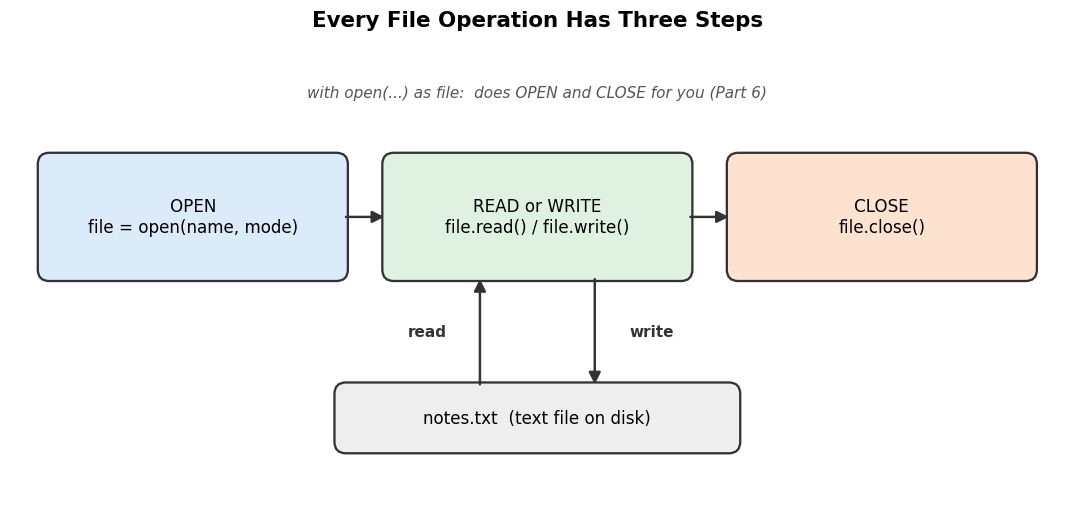

In [ ]:
# Example 1: Open, write, close - then open, read, close
file = open('hello.txt', 'w', encoding='utf-8')   # 'w' creates the file
file.write('Hello, file!')
file.close()

file = open('hello.txt', 'r', encoding='utf-8')   # 'r' opens it for reading
content = file.read()
file.close()
print(content)
# Expected output: Hello, file!

In [ ]:
# Example 2: The file object and its closed attribute
file = open('hello.txt', 'r', encoding='utf-8')
print(file.name)
print(file.mode)
print(file.closed)
file.close()
print(file.closed)
# Expected output:
# hello.txt
# r
# False
# True

In [ ]:
# Example 3: A closed file cannot be used any more
file = open('hello.txt', 'r', encoding='utf-8')
file.close()
# file.read()   # ValueError: I/O operation on closed file.
print('Open the file again if you need it')
# Expected output: Open the file again if you need it

In [ ]:
# Example 4: Reading a file that does not exist
# open('missing.txt', 'r')   # FileNotFoundError: [Errno 2] No such file or directory: 'missing.txt'
print('Mode r needs the file to exist already')
# Expected output: Mode r needs the file to exist already

---
# Part 3: File Modes

| Mode | Name | If the file exists | If it does not exist | Read? | Write? | Starts at |
|---|---|---|---|---|---|---|
| `'r'` | Read (default) | Opens it | **FileNotFoundError** | Yes | No | Beginning |
| `'w'` | Write | **Erases everything** first | Creates it | No | Yes | Beginning |
| `'a'` | Append | Keeps the content | Creates it | No | Yes | End |
| `'x'` | Exclusive create | **FileExistsError** | Creates it | No | Yes | Beginning |
| `'r+'` | Read and write | Opens it | FileNotFoundError | Yes | Yes | Beginning |
| `'w+'` | Write and read | Erases everything first | Creates it | Yes | Yes | Beginning |
| `'a+'` | Append and read | Keeps the content | Creates it | Yes | Yes (always at the end) | End |

**Warning:** `'w'` deletes the old contents the moment the file is opened, even if you write nothing. Use `'a'` to add to a file, or `'x'` to make sure you never overwrite one.

**Diagram: What each file mode does**

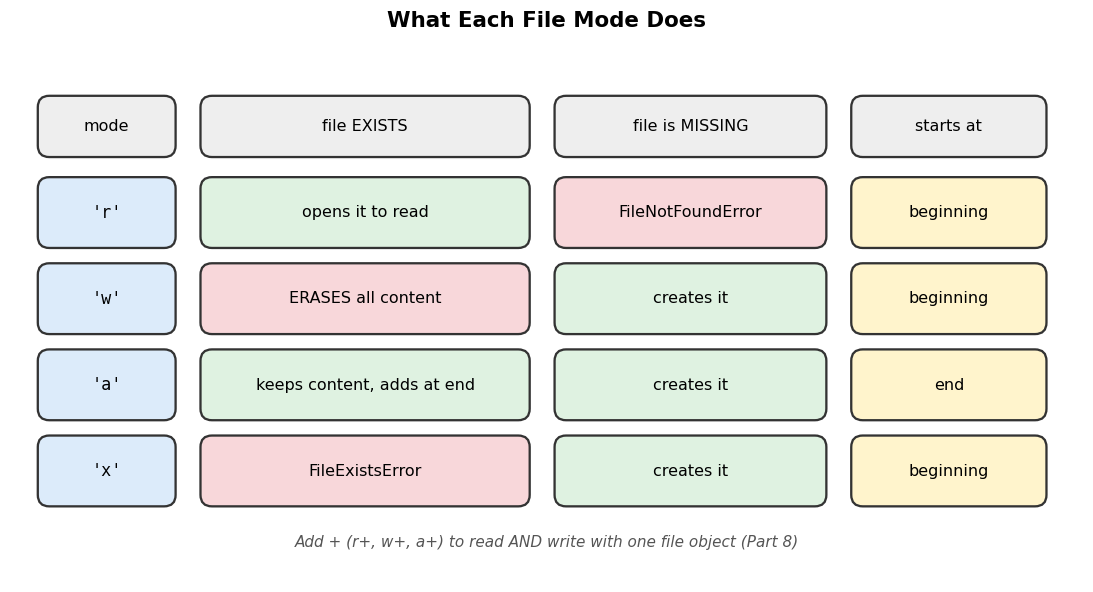

In [ ]:
# Example 1: 'w' overwrites the whole file
file = open('modes.txt', 'w', encoding='utf-8')
file.write('First version')
file.close()

file = open('modes.txt', 'w', encoding='utf-8')
file.write('Second version')
file.close()

file = open('modes.txt', 'r', encoding='utf-8')
print(file.read())
file.close()
# Expected output: Second version

In [ ]:
# Example 2: 'a' adds to the end and keeps the old content
file = open('modes.txt', 'a', encoding='utf-8')
file.write(' + appended text')
file.close()

file = open('modes.txt', 'r', encoding='utf-8')
print(file.read())
file.close()
# Expected output: Second version + appended text

In [ ]:
# Example 3: 'x' creates a NEW file only, and refuses to overwrite
import os
if os.path.exists('unique.txt'):
    os.remove('unique.txt')       # remove it so this example can be re-run (Part 9)

file = open('unique.txt', 'x', encoding='utf-8')
file.write('Created safely')
file.close()
print('unique.txt created')
# open('unique.txt', 'x')   # FileExistsError: [Errno 17] File exists: 'unique.txt'
# Expected output: unique.txt created

In [ ]:
# Example 4: Opening with 'w' empties a file even if you write nothing
file = open('modes.txt', 'w', encoding='utf-8')
file.close()

file = open('modes.txt', 'r', encoding='utf-8')
content = file.read()
file.close()
print(repr(content), len(content))
# Expected output: '' 0

---
# Part 4: Writing to a File

| Method | What it does |
|---|---|
| `file.write(text)` | Writes one string and **returns the number of characters** written. It does **not** add a new line |
| `file.writelines(list_of_strings)` | Writes every string in a list, one after another. It also does **not** add new lines |
| `print(..., file=file)` | Works like the normal `print()`, but sends the text to the file, **with** a new line at the end |

To end a line yourself, add the **newline character** `'\n'` (a backslash followed by n). It is one invisible character that means: start a new line.

**Only strings can be written.** Convert numbers first with `str()` or an f-string.

In [ ]:
# Example 1: write() does not add new lines by itself
file = open('lines.txt', 'w', encoding='utf-8')
file.write('Apple')
file.write('Banana')
file.close()

file = open('lines.txt', 'r', encoding='utf-8')
print(file.read())
file.close()
# Expected output: AppleBanana

In [ ]:
# Example 2: Add '\n' at the end of each line
file = open('lines.txt', 'w', encoding='utf-8')
file.write('Apple\n')
file.write('Banana\n')
file.write('Cherry\n')
file.close()

file = open('lines.txt', 'r', encoding='utf-8')
print(file.read(), end='')   # end='' because the text already ends with a new line
file.close()
# Expected output:
# Apple
# Banana
# Cherry

In [ ]:
# Example 3: write() returns the number of characters, and needs strings
file = open('numbers.txt', 'w', encoding='utf-8')
count = file.write('Total: ' + str(250) + '\n')
print('Characters written:', count)
# file.write(250)   # TypeError: write() argument must be str, not int
file.write(f'Average: {83.5}\n')
file.close()

file = open('numbers.txt', 'r', encoding='utf-8')
print(file.read(), end='')
file.close()
# Expected output:
# Characters written: 11
# Total: 250
# Average: 83.5

In [ ]:
# Example 4: writelines() writes a whole list of strings
fruits = ['Mango\n', 'Grapes\n', 'Orange\n']
file = open('fruits.txt', 'w', encoding='utf-8')
file.writelines(fruits)
file.close()

file = open('fruits.txt', 'r', encoding='utf-8')
print(file.read(), end='')
file.close()
# Expected output:
# Mango
# Grapes
# Orange

In [ ]:
# Example 5: Writing the items of a list, one per line, with a loop
students = ['Asha', 'Ravi', 'Meena']
file = open('students.txt', 'w', encoding='utf-8')
for name in students:
    file.write(name + '\n')
file.close()

file = open('students.txt', 'r', encoding='utf-8')
print(file.read(), end='')
file.close()
# Expected output:
# Asha
# Ravi
# Meena

In [ ]:
# Example 6: print(file=...) adds the new line for you and accepts numbers
file = open('report.txt', 'w', encoding='utf-8')
print('Marks Report', file=file)
print('Asha', 91, file=file)
print('Ravi', 78, file=file)
file.close()

file = open('report.txt', 'r', encoding='utf-8')
print(file.read(), end='')
file.close()
# Expected output:
# Marks Report
# Asha 91
# Ravi 78

In [ ]:
# Example 7: Saving user input to a file
note = input('Write a short note: ')
file = open('note.txt', 'w', encoding='utf-8')
file.write(note + '\n')
file.close()
print('Saved to note.txt')
# Example run:
# Write a short note: Buy milk
# Saved to note.txt

---
# Part 5: Reading a File

| Method | Returns | Best for |
|---|---|---|
| `file.read()` | The **whole file** as one string | Small files |
| `file.read(n)` | The next **n characters** | Reading in pieces |
| `file.readline()` | The **next line**, including its `'\n'`; an empty string `''` at the end of the file | One line at a time |
| `file.readlines()` | A **list** of all lines, each with its `'\n'` | When you need a list |
| `for line in file:` | One line per loop round | Big files: it reads one line at a time and saves memory |

Lines read from a file keep their `'\n'` at the end. Use `line.strip()` to remove it (it also removes spaces at both ends).

**Diagram: Four ways to read a text file**

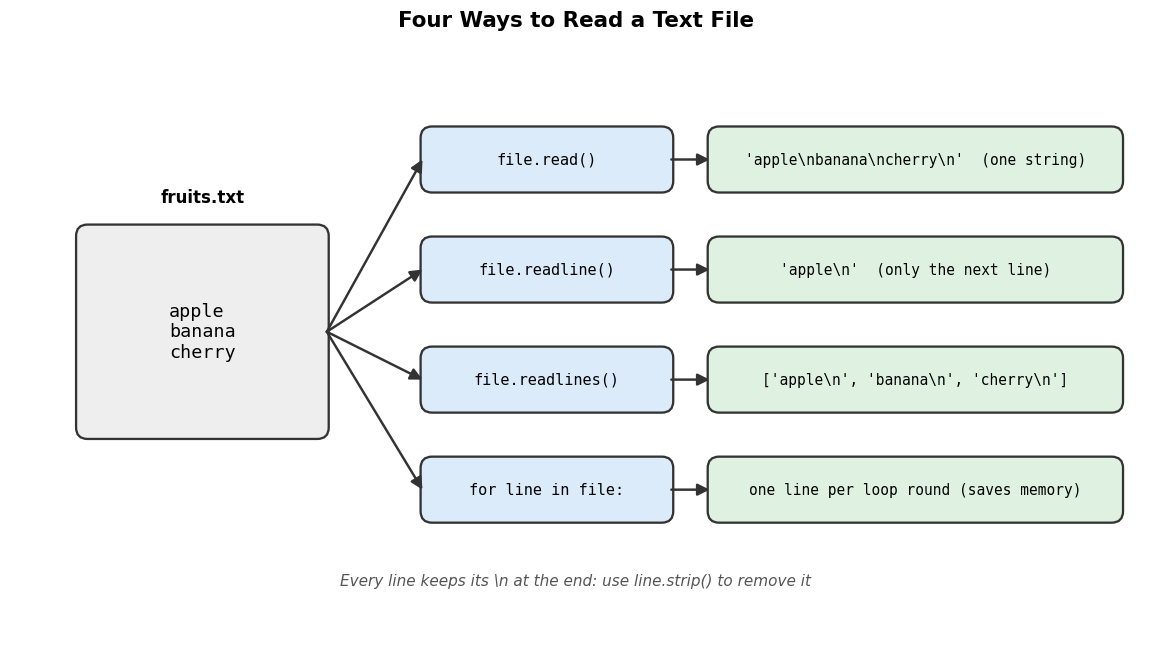

In [ ]:
# Setup: create a sample file used in the examples below
file = open('poem.txt', 'w', encoding='utf-8')
file.write('Twinkle twinkle little star\n')
file.write('How I wonder what you are\n')
file.write('Up above the world so high\n')
file.close()
print('poem.txt is ready')
# Expected output: poem.txt is ready

In [ ]:
# Example 1: read() - the whole file as one string
file = open('poem.txt', 'r', encoding='utf-8')
content = file.read()
file.close()
print(content, end='')
print('Type:', type(content))
print('Characters:', len(content))
# Expected output:
# Twinkle twinkle little star
# How I wonder what you are
# Up above the world so high
# Type: <class 'str'>
# Characters: 81

In [ ]:
# Example 2: read(n) - a few characters at a time
file = open('poem.txt', 'r', encoding='utf-8')
print(file.read(7))     # the first 7 characters
print(file.read(8))     # the NEXT 8 characters: reading continues where it stopped
file.close()
# Expected output:
# Twinkle
#  twinkle      (starts with a space)

In [ ]:
# Example 3: readline() - one line at a time
file = open('poem.txt', 'r', encoding='utf-8')
line1 = file.readline()
line2 = file.readline()
file.close()
print(repr(line1))       # repr() shows the hidden '\n'
print(line2.strip())     # strip() removes it
# Expected output:
# 'Twinkle twinkle little star\n'
# How I wonder what you are

In [ ]:
# Example 4: readline() gives an empty string at the end of the file
file = open('poem.txt', 'r', encoding='utf-8')
while True:
    line = file.readline()
    if line == '':          # end of the file reached
        break
    print('Read:', line.strip())
file.close()
# Expected output:
# Read: Twinkle twinkle little star
# Read: How I wonder what you are
# Read: Up above the world so high

In [ ]:
# Example 5: readlines() - a list of all lines
file = open('poem.txt', 'r', encoding='utf-8')
lines = file.readlines()
file.close()
print(lines)
print('Number of lines:', len(lines))
print('Last line:', lines[-1].strip())
# Expected output:
# ['Twinkle twinkle little star\n', 'How I wonder what you are\n', 'Up above the world so high\n']
# Number of lines: 3
# Last line: Up above the world so high

In [ ]:
# Example 6: Looping over the file - the best way for big files
file = open('poem.txt', 'r', encoding='utf-8')
for number, line in enumerate(file, start=1):
    print(number, line.strip())
file.close()
# Expected output:
# 1 Twinkle twinkle little star
# 2 How I wonder what you are
# 3 Up above the world so high

In [ ]:
# Example 7: After reading to the end, reading again gives nothing (Part 8 explains why)
file = open('poem.txt', 'r', encoding='utf-8')
first = file.read()
second = file.read()
file.close()
print(len(first), repr(second))
# Expected output: 81 ''

---
# Part 6: The with Statement (Recommended)

**Syntax:**
```python
with open(filename, mode, encoding='utf-8') as file:
    # use the file here (indented block)
# here the file is already closed
```

`with` **closes the file automatically** when the indented block ends, even if an error happens inside the block. You can never forget `close()`.

From now on, this lab uses `with` for every file.

**Diagram: Why use the with statement**

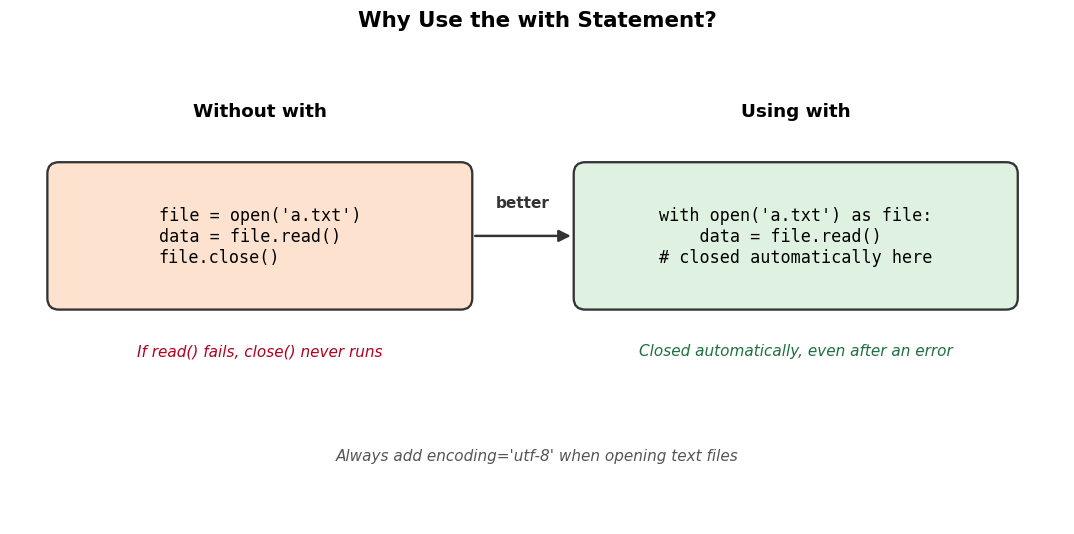

In [ ]:
# Example 1: Writing and reading with 'with'
with open('diary.txt', 'w', encoding='utf-8') as file:
    file.write('Day 1: Started learning file handling\n')
    file.write('Day 2: Learned the with statement\n')

with open('diary.txt', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# Day 1: Started learning file handling
# Day 2: Learned the with statement

In [ ]:
# Example 2: The file is closed automatically after the block
with open('diary.txt', 'r', encoding='utf-8') as file:
    print('Inside the block, closed =', file.closed)
print('After the block, closed =', file.closed)
# Expected output:
# Inside the block, closed = False
# After the block, closed = True

In [ ]:
# Example 3: Two files in one with statement - copying a file
with open('diary.txt', 'r', encoding='utf-8') as source, open('diary_copy.txt', 'w', encoding='utf-8') as copy:
    for line in source:
        copy.write(line)

with open('diary_copy.txt', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# Day 1: Started learning file handling
# Day 2: Learned the with statement

In [ ]:
# Example 4: Reusable functions for writing and reading lists of lines
def write_lines(filename, items):
    """Write each item on its own line (items can be any values)."""
    with open(filename, 'w', encoding='utf-8') as file:
        for item in items:
            file.write(str(item) + '\n')

def read_lines(filename):
    """Return the lines of a text file as a list, without new-line characters."""
    lines = []
    with open(filename, 'r', encoding='utf-8') as file:
        for line in file:
            lines.append(line.strip())
    return lines

write_lines('cities.txt', ['Delhi', 'Mumbai', 'Chennai'])
print(read_lines('cities.txt'))
# Expected output: ['Delhi', 'Mumbai', 'Chennai']

---
# Part 7: Appending to a File

Mode `'a'` adds new text **at the end** and keeps everything already in the file. If the file does not exist, it is created.

Typical uses: log files, chat history, diaries, adding new records.

In [ ]:
# Example 1: Adding items to a shopping list
with open('shopping.txt', 'w', encoding='utf-8') as file:     # start with a fresh file
    file.write('Milk\n')

with open('shopping.txt', 'a', encoding='utf-8') as file:
    file.write('Bread\n')
    file.write('Eggs\n')

with open('shopping.txt', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# Milk
# Bread
# Eggs

In [ ]:
# Example 2: A simple log file, one line per event
def log(message, filename='app_log.txt'):
    """Add one message to the end of the log file."""
    with open(filename, 'a', encoding='utf-8') as file:
        file.write(message + '\n')

with open('app_log.txt', 'w', encoding='utf-8') as file:   # clear the old log
    pass

log('App started')
log('User Asha logged in')
log('User Asha logged out')

with open('app_log.txt', 'r', encoding='utf-8') as file:
    for number, line in enumerate(file, start=1):
        print(f'{number}. {line.strip()}')
# Expected output:
# 1. App started
# 2. User Asha logged in
# 3. User Asha logged out

In [ ]:
# Example 3: Keep adding to-do items until the user types done
with open('todo.txt', 'a', encoding='utf-8') as file:
    pass                                   # makes sure the file exists

while True:
    task = input('Add a task (or done): ')
    if task == 'done':
        break
    with open('todo.txt', 'a', encoding='utf-8') as file:
        file.write(task + '\n')

with open('todo.txt', 'r', encoding='utf-8') as file:
    print('Your tasks:')
    print(file.read(), end='')
# Example run (first time):
# Add a task (or done): Study Python
# Add a task (or done): Call mom
# Add a task (or done): done
# Your tasks:
# Study Python
# Call mom
# Run the cell again: the old tasks are still there, because 'a' keeps them.

---
# Part 8: The File Pointer - tell() and seek()

An open file has an invisible **pointer** (cursor) that marks the current position. Every read or write starts at the pointer and moves it forward.

| Method | What it does |
|---|---|
| `file.tell()` | Returns the current position. For plain English text, this is the number of characters from the start |
| `file.seek(0)` | Moves the pointer back to the **start** of the file |
| `file.seek(0, 2)` | Moves the pointer to the **end** of the file |

With special characters (emoji, Hindi letters), positions count bytes instead of characters, so only `seek()` to 0 or to a number that `tell()` gave you.

The positions in these examples are for Colab and Linux. On Windows, every new line takes 2 positions, so some numbers will be bigger.

The `+` modes let you read **and** write with one file object, so `seek()` becomes important:
- `'r+'`: read and write, starting at the beginning; the file must exist
- `'w+'`: erases the file, then read and write
- `'a+'`: read and write, but every write goes to the end

**Diagram: The file pointer**

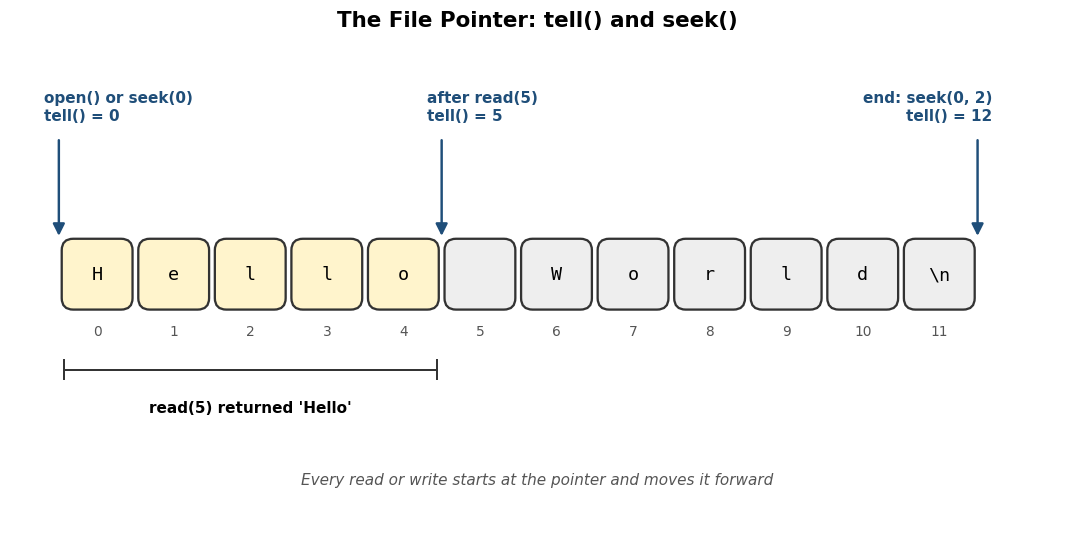

In [ ]:
# Example 1: tell() shows where the pointer is
with open('poem.txt', 'r', encoding='utf-8') as file:
    print(file.tell())
    file.read(7)
    print(file.tell())
    file.readline()          # reads the rest of line 1, including its new line
    print(file.tell())
# Expected output:
# 0
# 7
# 28

In [ ]:
# Example 2: seek(0) goes back to the start so the file can be read again
with open('poem.txt', 'r', encoding='utf-8') as file:
    first_line = file.readline().strip()
    file.seek(0)
    again = file.readline().strip()
print(first_line)
print(again)
# Expected output:
# Twinkle twinkle little star
# Twinkle twinkle little star

In [ ]:
# Example 3: 'w+' - write, then seek(0) and read it back with the same file object
with open('scratch.txt', 'w+', encoding='utf-8') as file:
    file.write('Line A\nLine B\n')
    print('Pointer after writing:', file.tell())
    print('Read without seek:', repr(file.read()))   # the pointer is at the end
    file.seek(0)
    print(file.read(), end='')
# Expected output:
# Pointer after writing: 14
# Read without seek: ''
# Line A
# Line B

In [ ]:
# Example 4: 'r+' - read and write in an existing file
with open('scratch.txt', 'r+', encoding='utf-8') as file:
    file.write('LINE')         # overwrites the first 4 characters
    file.seek(0)
    print(file.read(), end='')
# Expected output:
# LINE A
# Line B

In [ ]:
# Example 5: 'a+' - writes always go to the end; seek(0) to read everything
with open('scratch.txt', 'a+', encoding='utf-8') as file:
    file.write('Line C\n')
    file.seek(0)
    print(file.read(), end='')
# Expected output:
# LINE A
# Line B
# Line C

---
# Part 9: Checking, Renaming and Deleting Files

The built-in `os` module talks to the operating system.

| Function | What it does |
|---|---|
| `os.path.exists(path)` | `True` if the file (or folder) exists |
| `os.path.getsize(path)` | Size of the file in bytes |
| `os.rename(old, new)` | Renames a file |
| `os.remove(path)` | Deletes a file (there is no recycle bin!) |
| `os.mkdir(name)` | Creates a folder |
| `os.path.join(folder, file)` | Builds a path with the correct separator for your system |

Check with `os.path.exists()` before reading or deleting, to avoid errors. (Part 19 shows another way: `try` and `except`.)

In [ ]:
# Example 1: Check before you read
import os
for name in ['poem.txt', 'missing.txt']:
    if os.path.exists(name):
        print(name, 'exists, size:', os.path.getsize(name), 'bytes')
    else:
        print(name, 'was not found')
# Expected output:
# poem.txt exists, size: 81 bytes
# missing.txt was not found

In [ ]:
# Example 2: Renaming a file
import os
with open('draft.txt', 'w', encoding='utf-8') as file:
    file.write('Version 1\n')

if os.path.exists('final.txt'):
    os.remove('final.txt')        # so the example can be re-run
os.rename('draft.txt', 'final.txt')
print(os.path.exists('draft.txt'), os.path.exists('final.txt'))
# Expected output: False True

In [ ]:
# Example 3: Deleting a file safely
import os
filename = 'final.txt'
if os.path.exists(filename):
    os.remove(filename)
    print(filename, 'deleted')
else:
    print(filename, 'does not exist')
print(os.path.exists(filename))
# Expected output:
# final.txt deleted
# False

In [ ]:
# Example 4: Creating a folder and saving a file inside it
import os
if not os.path.exists('reports'):
    os.mkdir('reports')
path = os.path.join('reports', 'january.txt')
print(path)
with open(path, 'w', encoding='utf-8') as file:
    file.write('January sales: 52000\n')
print(os.path.exists(path))
# Expected output:
# reports/january.txt   (on Windows the separator is a backslash)
# True

In [ ]:
# Example 5: A function that reads a file only if it exists
import os
def safe_read(filename):
    """Return the file's text, or a message if the file is missing."""
    if not os.path.exists(filename):
        return f'[{filename} not found]'
    with open(filename, 'r', encoding='utf-8') as file:
        return file.read()

print(safe_read(os.path.join('reports', 'january.txt')), end='')
print(safe_read('nothing.txt'))
# Expected output:
# January sales: 52000
# [nothing.txt not found]

---
# Part 10: Processing Text Files

Most real tasks follow the same pattern: **read** the file, **process** each line with string methods, loops and conditions, then **print** or **write** the result.

| String method | Example | Result |
|---|---|---|
| `strip()` | `'  hi\n'.strip()` | `'hi'` |
| `split()` | `'a b  c'.split()` | `['a', 'b', 'c']` |
| `split(',')` | `'Asha,91'.split(',')` | `['Asha', '91']` |
| `lower()` | `'Star'.lower()` | `'star'` |
| `replace(old, new)` | `'cat'.replace('c', 'b')` | `'bat'` |
| `startswith(text)` | `'#note'.startswith('#')` | `True` |
| `join(list)` | `', '.join(['a', 'b'])` | `'a, b'` |

In [ ]:
# Setup: a small story file for the examples below
with open('story.txt', 'w', encoding='utf-8') as file:
    file.write('Python is easy to learn.\n')
    file.write('Python is used for data science.\n')
    file.write('Many students love Python.\n')
print('story.txt is ready')
# Expected output: story.txt is ready

In [ ]:
# Example 1: Count lines, words and characters
line_count = 0
word_count = 0
char_count = 0
with open('story.txt', 'r', encoding='utf-8') as file:
    for line in file:
        line_count += 1
        word_count += len(line.split())
        char_count += len(line.strip())
print('Lines:', line_count)
print('Words:', word_count)
print('Characters (without new lines):', char_count)
# Expected output:
# Lines: 3
# Words: 15
# Characters (without new lines): 82

In [ ]:
# Example 2: Find the lines that contain a phrase (ignoring capital letters)
search = 'python is'
with open('story.txt', 'r', encoding='utf-8') as file:
    for number, line in enumerate(file, start=1):
        if search in line.lower():
            print(f'Line {number}: {line.strip()}')
# Expected output:
# Line 1: Python is easy to learn.
# Line 2: Python is used for data science.

In [ ]:
# Example 3: How often does each word appear? (a dictionary of counts)
counts = {}
with open('story.txt', 'r', encoding='utf-8') as file:
    for line in file:
        for word in line.lower().replace('.', '').split():
            counts[word] = counts.get(word, 0) + 1

top = sorted(counts.items(), key=lambda pair: pair[1], reverse=True)
print(top[:3])
# Expected output: [('python', 3), ('is', 2), ('easy', 1)]

In [ ]:
# Example 4: Find and replace - write the changed text to a new file
with open('story.txt', 'r', encoding='utf-8') as file:
    text = file.read()

new_text = text.replace('Python', 'Java')
with open('story_java.txt', 'w', encoding='utf-8') as file:
    file.write(new_text)

with open('story_java.txt', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# Java is easy to learn.
# Java is used for data science.
# Many students love Java.

In [ ]:
# Example 5: Reading numbers from a file (text must be converted with int or float)
with open('scores.txt', 'w', encoding='utf-8') as file:
    file.write('78\n92\n65\n88\n')

scores = []
with open('scores.txt', 'r', encoding='utf-8') as file:
    for line in file:
        scores.append(int(line))      # int() ignores the new line at the end
print(scores)
print('Total:', sum(scores), 'Average:', sum(scores) / len(scores))
# Expected output:
# [78, 92, 65, 88]
# Total: 323 Average: 80.75

In [ ]:
# Example 6: Records with fields separated by commas
with open('marks.txt', 'w', encoding='utf-8') as file:
    file.write('Asha,Maths,91\n')
    file.write('Ravi,Maths,37\n')
    file.write('Meena,Maths,84\n')

with open('marks.txt', 'r', encoding='utf-8') as file:
    for line in file:
        name, subject, marks = line.strip().split(',')
        result = 'Pass' if int(marks) >= 40 else 'Fail'
        print(f'{name:<6} {subject:<6} {marks:>3}  {result}')
# Expected output:
# Asha   Maths   91  Pass
# Ravi   Maths   37  Fail
# Meena  Maths   84  Pass

In [ ]:
# Example 7: A settings file - skipping blank lines and comment lines
with open('settings.txt', 'w', encoding='utf-8') as file:
    file.write('# App settings\n')
    file.write('theme=dark\n')
    file.write('\n')
    file.write('language=English\n')

settings = {}
with open('settings.txt', 'r', encoding='utf-8') as file:
    for line in file:
        line = line.strip()
        if line == '' or line.startswith('#'):
            continue                      # skip blank and comment lines
        key, value = line.split('=')
        settings[key] = value
print(settings)
# Expected output: {'theme': 'dark', 'language': 'English'}

In [ ]:
# Example 8: Writing a formatted report from a dictionary
prices = {'Pen': 10, 'Notebook': 45, 'Bag': 750}
with open('price_list.txt', 'w', encoding='utf-8') as file:
    file.write('PRICE LIST\n')
    for item, price in prices.items():
        file.write(f'{item}: Rs. {price}\n')
    file.write(f'Items: {len(prices)}\n')

with open('price_list.txt', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# PRICE LIST
# Pen: Rs. 10
# Notebook: Rs. 45
# Bag: Rs. 750
# Items: 3

---
# Section B: Exception Handling

Parts 11 to 21: dealing with errors gracefully, including the errors that happen while working with files.

# Part 11: Three Kinds of Errors

| Kind | When it is found | Example | Does the program run? |
|---|---|---|---|
| **Syntax error** | Before running, while Python reads the code | `print('hi'` (missing bracket) | No, nothing runs |
| **Exception** (runtime error) | While the program is running | `10 / 0` | It stops at that line, unless the error is handled |
| **Logical error** | Never reported by Python | using `+` where you needed `*` | Yes, but the answers are wrong |

Exception handling deals with the **second** kind. Syntax errors must be fixed in the code, and logical errors are found by testing.

### Reading an Error Message (Traceback)
```
Traceback (most recent call last):
  Cell In[3], line 3
    result = price / quantity
ZeroDivisionError: division by zero
```
| Part | Meaning |
|---|---|
| Last line | The **exception type** and a **message**: the most important part |
| `line 3` | Where the error happened |
| The code line | The statement that failed |

**Tip:** read the **last line first**. (The first lines look slightly different in Colab and Jupyter.)

In [ ]:
# Example 1: An unhandled exception stops the program at that line
print('Step 1')
print('Step 2')
# print(10 / 0)     # uncomment: ZeroDivisionError, and Step 3 would never print
print('Step 3')
# Expected output:
# Step 1
# Step 2
# Step 3

In [ ]:
# Example 2: Try it - uncomment the line to see a real traceback, read it, then comment it again
price = 500
quantity = 0
# result = price / quantity
print('Uncomment the line above to see the error')
# Expected output: Uncomment the line above to see the error

---
# Part 12: Common Built-in Exceptions

| Exception | Raised when | Example |
|---|---|---|
| `ZeroDivisionError` | Dividing by zero | `10 / 0` |
| `ValueError` | The type is right but the value is wrong | `int('abc')` |
| `TypeError` | The operation does not work for that type | `'5' + 5` |
| `NameError` | A name is not defined (often a typo) | `print(totl)` |
| `IndexError` | A list position does not exist | `[1, 2, 3][5]` |
| `KeyError` | A dictionary key does not exist | `{'a': 1}['b']` |
| `AttributeError` | The value has no such method | `(5).append(1)` |
| `FileNotFoundError` | The file does not exist | `open('nope.txt')` |
| `ModuleNotFoundError` | The module cannot be imported | `import mathz` |
| `UnboundLocalError` | A global is changed inside a function without `global` | Functions lab, Part 8 |
| `RecursionError` | Recursion goes too deep (no base case) | Functions lab, Part 12 |
| `StopIteration` | `next()` on a finished generator | Functions lab, Part 13 |

Exceptions form a **family tree**: for example, `ZeroDivisionError` is a kind of `ArithmeticError`, and almost every error is a kind of `Exception`.

**Diagram: The exception family tree**

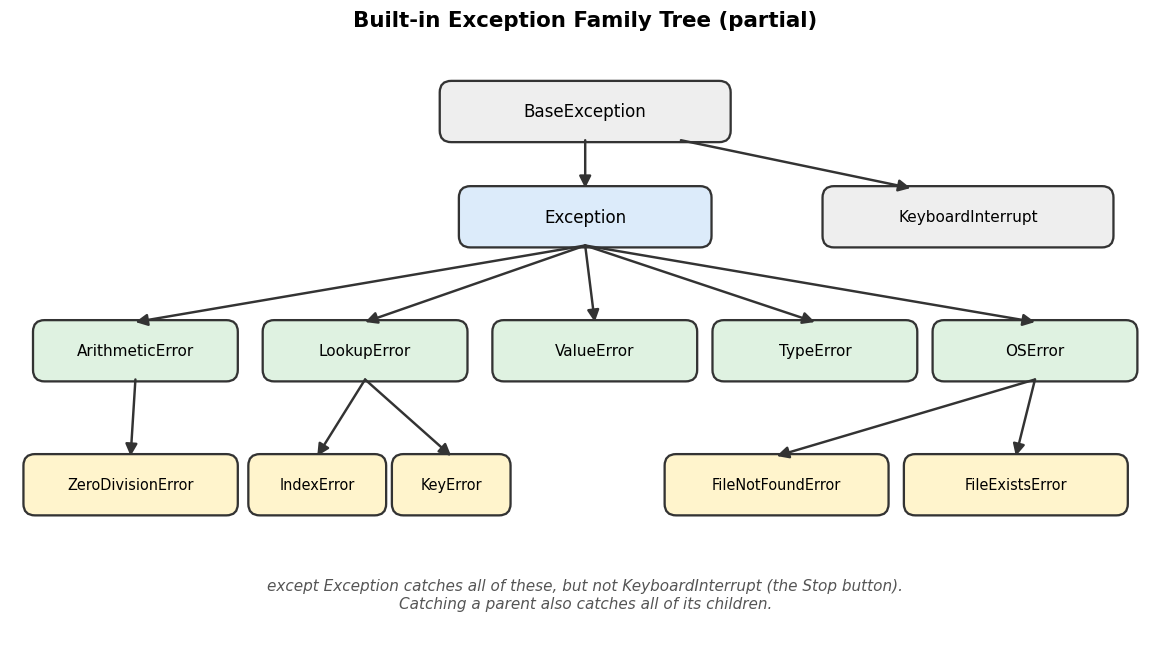

In [ ]:
# Each line below raises a different exception.
# Uncomment ONE line at a time, run the cell, read the last line of the error, then comment it again.

# print(10 / 0)            # ZeroDivisionError: division by zero
# int('abc')               # ValueError: invalid literal for int() with base 10: 'abc'
# '5' + 5                  # TypeError: can only concatenate str (not "int") to str
# print(totl)              # NameError: name 'totl' is not defined
# [1, 2, 3][5]             # IndexError: list index out of range
# {'a': 1}['b']            # KeyError: 'b'
# (5).append(1)            # AttributeError: 'int' object has no attribute 'append'
# open('nope.txt')         # FileNotFoundError: [Errno 2] No such file or directory: 'nope.txt'
# import mathz             # ModuleNotFoundError: No module named 'mathz'
print('All the error lines are commented out, so nothing breaks')
# Expected output: All the error lines are commented out, so nothing breaks

---
# Part 13: try and except

**Syntax:**
```python
try:
    # code that might fail
except ExceptionName:
    # runs ONLY if that error happened in the try block
```

**How it works**
1. Python runs the `try` block.
2. If **no error** happens, the `except` block is **skipped**.
3. If an error happens, Python **jumps immediately** to `except`; the rest of the `try` block is skipped.
4. Either way, the program **continues** after the whole `try-except`.

Always name the exception you expect, such as `except ValueError:`. Part 14 explains why.

**Diagram: How try-except works**

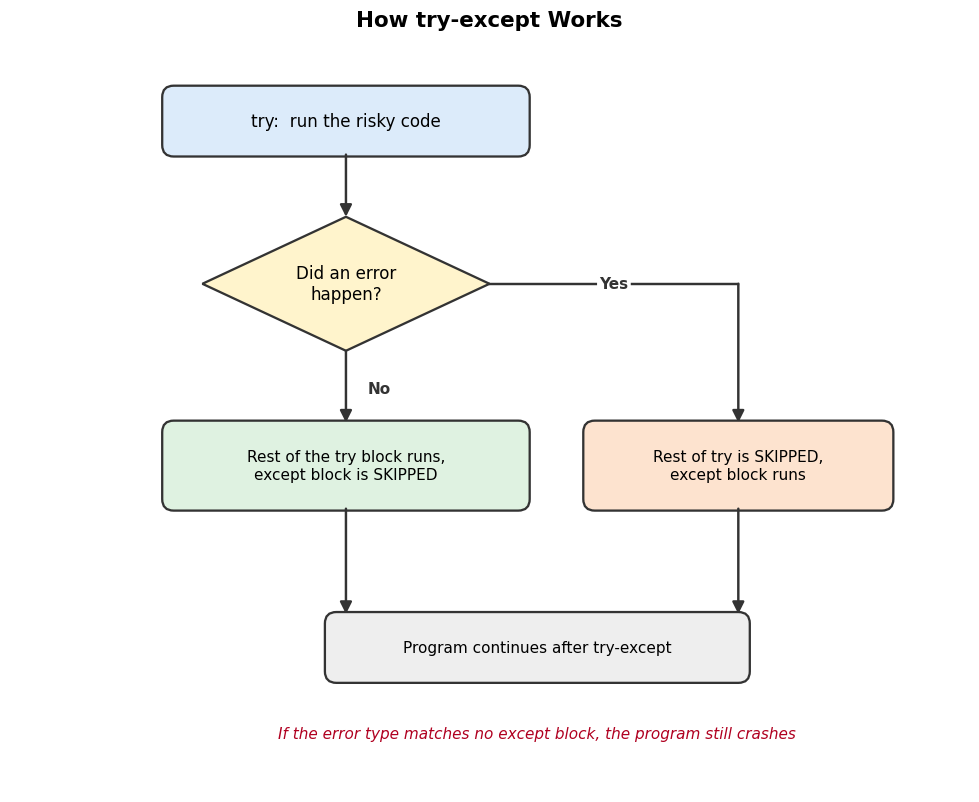

In [ ]:
# Example 1: try-except without and with an error
for divisor in [5, 0]:
    try:
        print('Trying 10 /', divisor)
        result = 10 / divisor
        print('Result:', result)
    except ZeroDivisionError:
        print('Cannot divide by zero!')
    print('Program continues')
# Expected output:
# Trying 10 / 5
# Result: 2.0
# Program continues
# Trying 10 / 0
# Cannot divide by zero!
# Program continues

In [ ]:
# Example 2: After the error, the rest of the try block is skipped
try:
    print('A')
    number = int('ten')       # ValueError happens here
    print('B')                # skipped
except ValueError:
    print('C: that was not a number')
print('D')
# Expected output:
# A
# C: that was not a number
# D

In [ ]:
# Example 3: Protecting user input
try:
    age = int(input('Enter your age: '))
    print('Next year you will be', age + 1)
except ValueError:
    print('Please enter digits only, like 25')
# Example run 1:
# Enter your age: 25
# Next year you will be 26
# Example run 2:
# Enter your age: twenty
# Please enter digits only, like 25

In [ ]:
# Example 4: Protecting a list lookup
fruits = ['apple', 'banana', 'mango']
for position in [1, 7]:
    try:
        print(position, '->', fruits[position])
    except IndexError:
        print(position, '-> no fruit at that position')
# Expected output:
# 1 -> banana
# 7 -> no fruit at that position

In [ ]:
# Example 5: Protecting a dictionary lookup
prices = {'pen': 10, 'book': 120}
for item in ['book', 'laptop']:
    try:
        print(item, 'costs', prices[item])
    except KeyError:
        print(item, 'is not sold here')
# Expected output:
# book costs 120
# laptop is not sold here

---
# Part 14: Catching Specific Exceptions

| Form | Meaning |
|---|---|
| `except ValueError:` | Catch one type |
| `except ValueError as e:` | Also store the error in `e`; `print(e)` shows its message |
| Several `except` blocks | A different reaction for each type. Python uses the **first** block that matches |
| `except (ValueError, TypeError):` | The same reaction for several types (written as a tuple) |
| `except Exception as e:` | Catch almost any error: use it only as a **last** safety net |

**Order matters:** put specific exceptions first and general ones (`Exception`) last. Otherwise the general block catches everything first.

**Avoid a bare `except:`** (with no name). It also hides your own mistakes, like typos in variable names, and even blocks stopping the program with the Stop button.

In [ ]:
# Example 1: Getting the error message with 'as'
try:
    number = int('12abc')
except ValueError as e:
    print('Error type:', type(e).__name__)     # the name of the error class
    print('Message:', e)
# Expected output:
# Error type: ValueError
# Message: invalid literal for int() with base 10: '12abc'

In [ ]:
# Example 2: A different message for each kind of problem
def divide(a, b):
    try:
        result = int(a) / int(b)
    except ValueError:
        return 'Both values must be whole numbers'
    except ZeroDivisionError:
        return 'The second number cannot be zero'
    return f'Result: {result}'

print(divide('10', '4'))
print(divide('10', 'x'))
print(divide('10', '0'))
# Expected output:
# Result: 2.5
# Both values must be whole numbers
# The second number cannot be zero

In [ ]:
# Example 3: One block for several exception types
items = [10, '20', None]
for item in items:
    try:
        print(item * 2 + 1)
    except (TypeError, ValueError) as e:
        print('Skipped', repr(item), 'because:', e)
# Expected output:
# 21
# Skipped '20' because: can only concatenate str (not "int") to str
# Skipped None because: unsupported operand type(s) for *: 'NoneType' and 'int'

In [ ]:
# Example 4: Order matters - specific first, general last
try:
    value = [1, 2, 3][10]
except IndexError:
    print('IndexError block ran')
except Exception:
    print('General block ran')

try:
    value = {'a': 1}['z']
except IndexError:
    print('IndexError block ran')
except Exception as e:
    print('General block ran for', type(e).__name__)
# Expected output:
# IndexError block ran
# General block ran for KeyError

In [ ]:
# Example 5: See many built-in exceptions safely (each lambda is a tiny risky function)
tests = [lambda: 10 / 0,
         lambda: int('abc'),
         lambda: '5' + 5,
         lambda: [1, 2][5],
         lambda: {'a': 1}['b'],
         lambda: open('nope.txt')]
for test in tests:
    try:
        test()
    except Exception as e:
        print(type(e).__name__, '->', e)
# Expected output:
# ZeroDivisionError -> division by zero
# ValueError -> invalid literal for int() with base 10: 'abc'
# TypeError -> can only concatenate str (not "int") to str
# IndexError -> list index out of range
# KeyError -> 'b'
# FileNotFoundError -> [Errno 2] No such file or directory: 'nope.txt'

---
# Part 15: else and finally

**Full syntax:**
```python
try:
    # code that might fail
except SomeError:
    # runs only if that error happened
else:
    # runs only if NO error happened
finally:
    # ALWAYS runs: error or not, even after return
```

| Block | Runs when | Typical use |
|---|---|---|
| `try` | always, first | the risky code |
| `except` | an error happened | report the problem or recover |
| `else` | no error happened | code that should run only after success |
| `finally` | always, at the end | clean-up: close files, print a final message |

**Diagram: try, except, else and finally**

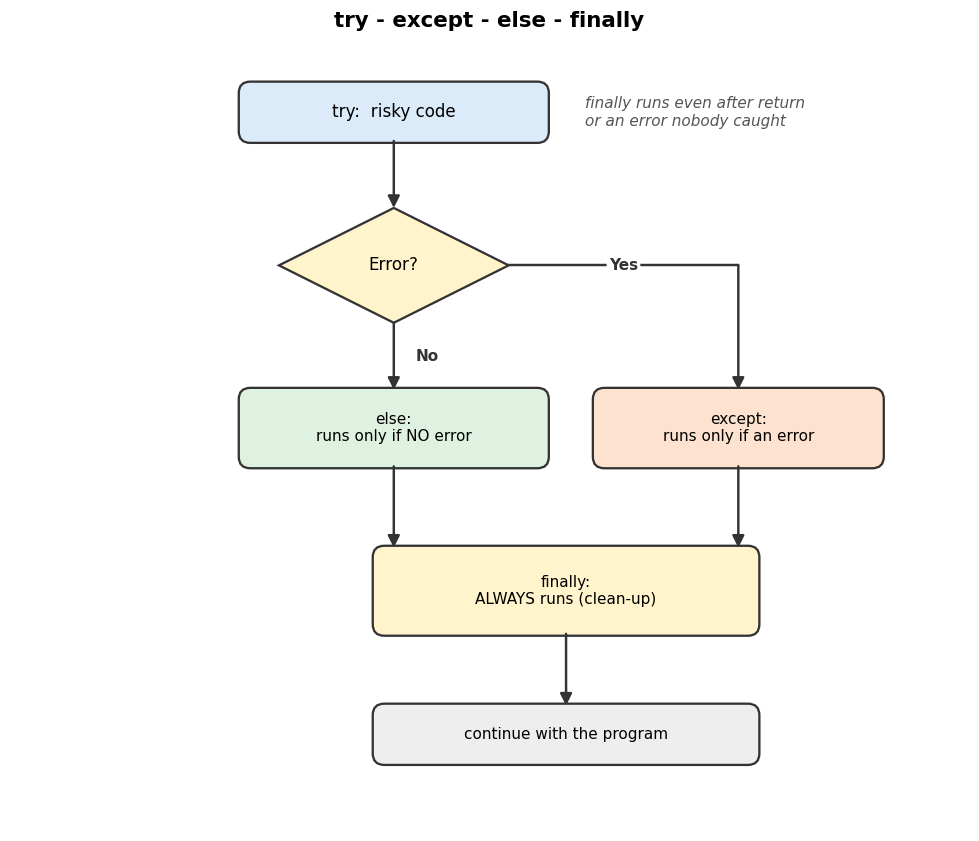

In [ ]:
# Example 1: All four blocks
def safe_divide(a, b):
    try:
        result = a / b
    except ZeroDivisionError:
        print('  except: cannot divide by zero')
    else:
        print('  else: result is', result)
    finally:
        print('  finally: division attempt finished')

print('10 / 2')
safe_divide(10, 2)
print('10 / 0')
safe_divide(10, 0)
# Expected output:
# 10 / 2
#   else: result is 5.0
#   finally: division attempt finished
# 10 / 0
#   except: cannot divide by zero
#   finally: division attempt finished

In [ ]:
# Example 2: Why use else? It keeps only the risky line inside try
text = '42'
try:
    number = int(text)            # the only line that can raise ValueError
except ValueError:
    print('Not a number')
else:
    print('Converted:', number)   # runs only after a successful conversion
    print('Doubled:', number * 2)
# Expected output:
# Converted: 42
# Doubled: 84

In [ ]:
# Example 3: finally runs even when the function returns early
def check(value):
    try:
        return 100 / value
    except ZeroDivisionError:
        return 'undefined'
    finally:
        print(f'  (finally ran for {value})')

print(check(4))
print(check(0))
# Expected output:
#   (finally ran for 4)
# 25.0
#   (finally ran for 0)
# undefined

In [ ]:
# Example 4: finally for clean-up - the file is closed even though processing fails
with open('mixed_numbers.txt', 'w', encoding='utf-8') as f:
    f.write('10\n20\nthirty\n40\n')

file = open('mixed_numbers.txt', 'r', encoding='utf-8')
try:
    total = 0
    for line in file:
        total += int(line)
    print('Total:', total)
except ValueError as e:
    print('Bad data:', e)
finally:
    file.close()                  # this is exactly what 'with' does for you (Part 6)
    print('File closed:', file.closed)
# Expected output:
# Bad data: invalid literal for int() with base 10: 'thirty\n'
# File closed: True

---
# Part 16: How Exceptions Travel Through Functions

If a function does not handle an error, the error **travels back up** to the code that called it, then to *its* caller, and so on. This is called **propagation**. The first matching `try-except` on the way up catches it. If nothing catches it, the program stops with a traceback.

This means you can handle errors in **one place** (for example, in the main menu) instead of inside every small function.

**Diagram: How an exception travels up**

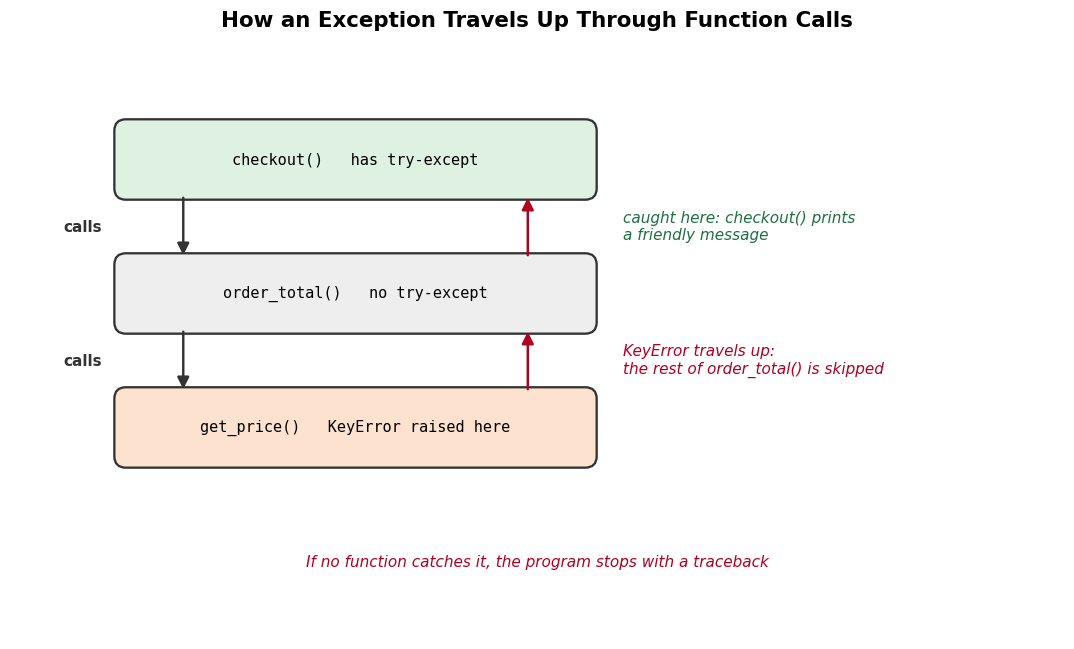

In [ ]:
# Example 1: An error raised deep inside is caught by the top-level caller
def get_price(item):
    prices = {'pen': 10, 'book': 120}
    return prices[item]                  # may raise KeyError

def order_total(item, quantity):
    return get_price(item) * quantity    # does not handle the error

def checkout(item, quantity):
    try:
        print(f'{item} x {quantity} = Rs. {order_total(item, quantity)}')
    except KeyError:
        print(f'Sorry, {item} is not available')

checkout('book', 2)
checkout('laptop', 1)
# Expected output:
# book x 2 = Rs. 240
# Sorry, laptop is not available

In [ ]:
# Example 2: Watch the error skip the rest of each function on its way up
def level3():
    print('  level3 starts')
    x = int('oops')
    print('  level3 ends')       # skipped

def level2():
    print(' level2 starts')
    level3()
    print(' level2 ends')        # skipped

def level1():
    print('level1 starts')
    try:
        level2()
    except ValueError:
        print('level1 caught the ValueError')
    print('level1 ends')

level1()
# Expected output:
# level1 starts
#  level2 starts
#   level3 starts
# level1 caught the ValueError
# level1 ends

---
# Part 17: Raising Exceptions with raise

You can **create** an error on purpose with `raise` when your code finds a value it must not accept.

**Syntax:**
```python
raise ValueError('a clear message explaining the problem')
```

**Why raise instead of just printing a message?**
- The caller **must** deal with it; it cannot be ignored by accident
- The function stops instead of continuing with bad data
- The caller decides how to react: show a message, ask again, or write to a log

Inside an `except` block, a bare `raise` **re-raises** the same error, for example after logging it.

In [ ]:
# Example 1: Raising an error for an invalid value
def set_age(age):
    if age < 0 or age > 120:
        raise ValueError(f'age must be between 0 and 120, got {age}')
    return age

print(set_age(25))
try:
    set_age(-5)
except ValueError as e:
    print('Error:', e)
# Expected output:
# 25
# Error: age must be between 0 and 120, got -5

In [ ]:
# Example 2: A bank withdrawal that refuses impossible requests
def withdraw(balance, amount):
    if amount <= 0:
        raise ValueError('amount must be positive')
    if amount > balance:
        raise ValueError(f'insufficient balance: {balance} available')
    return balance - amount

balance = 1000
for amount in [300, -50, 5000]:
    try:
        balance = withdraw(balance, amount)
        print(f'Withdrew {amount}, balance is now {balance}')
    except ValueError as e:
        print(f'Could not withdraw {amount}: {e}')
# Expected output:
# Withdrew 300, balance is now 700
# Could not withdraw -50: amount must be positive
# Could not withdraw 5000: insufficient balance: 700 available

In [ ]:
# Example 3: Raising TypeError for the wrong kind of value
def area_of_square(side):
    if not isinstance(side, (int, float)):
        raise TypeError('side must be a number')
    return side * side

for side in [4, 'four']:
    try:
        print(area_of_square(side))
    except TypeError as e:
        print('Error:', e)
# Expected output:
# 16
# Error: side must be a number

In [ ]:
# Example 4: Logging an error, then re-raising it for the caller
def convert(text):
    try:
        return int(text)
    except ValueError:
        print(f'  [log] could not convert {repr(text)}')
        raise                          # pass the same error on to the caller

try:
    convert('7')
    convert('seven')
except ValueError as e:
    print('Caller handled it:', e)
# Expected output:
#   [log] could not convert 'seven'
# Caller handled it: invalid literal for int() with base 10: 'seven'

---
# Part 18: Custom Exceptions

You can create your **own** exception types with meaningful names, like `InsufficientFundsError`. This needs one small piece of new syntax, `class`:

```python
class InsufficientFundsError(Exception):
    pass
```

- `class` creates a new type. (Classes are covered in detail in the OOP lab.)
- `(Exception)` means: this new type is a kind of `Exception`, so it behaves like the built-in ones.
- `pass` is enough: nothing else is needed.

By convention, exception names end with **Error**. You can also build a small **family**: a parent error plus more specific child errors. Catching the parent then catches all of its children.

In [ ]:
# Example 1: Defining and raising a custom exception
class InsufficientFundsError(Exception):
    pass

def withdraw(balance, amount):
    if amount > balance:
        raise InsufficientFundsError(f'tried to take {amount}, only {balance} available')
    return balance - amount

try:
    withdraw(500, 800)
except InsufficientFundsError as e:
    print('Transaction refused:', e)
# Expected output: Transaction refused: tried to take 800, only 500 available

In [ ]:
# Example 2: A family of custom exceptions
class ShopError(Exception):
    pass

class OutOfStockError(ShopError):        # a kind of ShopError
    pass

class InvalidQuantityError(ShopError):   # another kind of ShopError
    pass

stock = {'pen': 5, 'book': 0}

def buy(item, quantity):
    if quantity <= 0:
        raise InvalidQuantityError('quantity must be at least 1')
    if stock.get(item, 0) < quantity:
        raise OutOfStockError(f'not enough {item} in stock')
    stock[item] -= quantity
    return f'Bought {quantity} {item}'

for item, qty in [('pen', 2), ('book', 1), ('pen', 0)]:
    try:
        print(buy(item, qty))
    except ShopError as e:                # catches BOTH kinds of ShopError
        print(type(e).__name__, '->', e)
# Expected output:
# Bought 2 pen
# OutOfStockError -> not enough book in stock
# InvalidQuantityError -> quantity must be at least 1

---
# Part 19: Exceptions with Files

File operations can fail for reasons outside your program. Part 9 checked first with `os.path.exists()` (**look before you leap**). The Python style is often to simply **try it and handle the error** (**easier to ask forgiveness than permission**).

| Exception | When |
|---|---|
| `FileNotFoundError` | Reading a file that does not exist |
| `FileExistsError` | Mode `'x'` on a file that already exists |
| `PermissionError` | No permission to read or write that file or folder |
| `IsADirectoryError` | The name belongs to a folder, not a file |
| `OSError` | The parent of all the above: any file or system error |

In [ ]:
# Example 1: Handling a missing file
def read_file(filename):
    try:
        with open(filename, 'r', encoding='utf-8') as file:
            return file.read()
    except FileNotFoundError:
        return f'[{filename} does not exist]'

with open('greeting.txt', 'w', encoding='utf-8') as file:
    file.write('Hello from the file!')

print(read_file('greeting.txt'))
print(read_file('no_such_file.txt'))
# Expected output:
# Hello from the file!
# [no_such_file.txt does not exist]

In [ ]:
# Example 2: Never overwrite an existing file
import os

def create_new(filename, text):
    try:
        with open(filename, 'x', encoding='utf-8') as file:
            file.write(text)
        print(f'{filename} created')
    except FileExistsError:
        print(f'{filename} already exists, nothing changed')

if os.path.exists('notes_new.txt'):
    os.remove('notes_new.txt')   # so this example can be re-run

create_new('notes_new.txt', 'first version')
create_new('notes_new.txt', 'second version')
# Expected output:
# notes_new.txt created
# notes_new.txt already exists, nothing changed

In [ ]:
# Example 3: Processing a file line by line and skipping bad lines
with open('temperatures.txt', 'w', encoding='utf-8') as file:
    file.write('31.5\n29\nN/A\n33.2\nhot\n')

values = []
with open('temperatures.txt', 'r', encoding='utf-8') as file:
    for number, line in enumerate(file, start=1):
        try:
            values.append(float(line))
        except ValueError:
            print(f'Line {number}: skipped', repr(line.strip()))
print('Valid readings:', values)
print('Average:', round(sum(values) / len(values), 2))
# Expected output:
# Line 3: skipped 'N/A'
# Line 5: skipped 'hot'
# Valid readings: [31.5, 29.0, 33.2]
# Average: 31.23

In [ ]:
# Example 4: OSError catches every kind of file problem
import os
if not os.path.exists('my_folder'):
    os.mkdir('my_folder')

for name in ['no_such_file.txt', 'my_folder']:
    try:
        with open(name, 'r', encoding='utf-8') as file:
            print(file.read())
    except OSError as e:
        print(type(e).__name__, '->', name)
# Expected output (Colab, Linux, Mac):
# FileNotFoundError -> no_such_file.txt
# IsADirectoryError -> my_folder
# (On Windows the second line shows PermissionError)

---
# Part 20: Validating User Input

Combine `while True`, `try-except`, `break` and `continue` to **keep asking** until the user gives a valid answer. Put this logic in a **function** so you can reuse it everywhere.

In [ ]:
# Example 1: Keep asking until a whole number is entered
while True:
    try:
        quantity = int(input('How many tickets? '))
        break                              # a valid number: leave the loop
    except ValueError:
        print('Please type a whole number, like 3')
print('You booked', quantity, 'tickets')
# Example run:
# How many tickets? two
# Please type a whole number, like 3
# How many tickets? 2
# You booked 2 tickets

In [ ]:
# Example 2: A reusable input function with a range check
def get_number(prompt, low, high):
    """Ask until the user enters a whole number between low and high."""
    while True:
        try:
            value = int(input(prompt))
            if value < low or value > high:
                raise ValueError(f'must be between {low} and {high}')
            return value
        except ValueError as e:
            print('  Invalid:', e)

marks = get_number('Enter marks (0-100): ', 0, 100)
print('Saved marks:', marks)
# Example run:
# Enter marks (0-100): abc
#   Invalid: invalid literal for int() with base 10: 'abc'
# Enter marks (0-100): 150
#   Invalid: must be between 0 and 100
# Enter marks (0-100): 87
# Saved marks: 87

In [ ]:
# Example 3: Only 3 attempts allowed (for-else from the Control Flow lab)
PIN = '4321'
for attempt in range(1, 4):
    try:
        entered = input(f'Attempt {attempt} - enter your 4-digit PIN: ')
        if not entered.isdigit() or len(entered) != 4:
            raise ValueError('PIN must be exactly 4 digits')
        if entered != PIN:
            print('  Wrong PIN')
            continue
        print('  Access granted')
        break
    except ValueError as e:
        print('  Invalid:', e)
else:
    print('Card blocked after 3 attempts')
# Example run:
# Attempt 1 - enter your 4-digit PIN: 12
#   Invalid: PIN must be exactly 4 digits
# Attempt 2 - enter your 4-digit PIN: 1111
#   Wrong PIN
# Attempt 3 - enter your 4-digit PIN: 4321
#   Access granted

---
# Part 21: assert and Best Practices

### assert
`assert condition, 'message'` checks something that **must** be true. If it is false, Python raises `AssertionError` with your message.

Use `assert` to catch **your own** programming mistakes while developing and testing. Do **not** use it to check user input: assert checks can be switched off when Python runs in optimised mode.

In [ ]:
# Example 1: assert inside a function
def average(numbers):
    assert len(numbers) > 0, 'average() needs at least one number'
    return sum(numbers) / len(numbers)

print(average([10, 20, 30]))
try:
    average([])
except AssertionError as e:
    print('AssertionError:', e)
# Expected output:
# 20.0
# AssertionError: average() needs at least one number

In [ ]:
# Example 2: Quick self-tests with assert - silence means every test passed
def is_even(n):
    return n % 2 == 0

assert is_even(4) == True
assert is_even(7) == False
assert is_even(0) == True
print('All tests passed')
# Expected output: All tests passed

### Best Practices

| Do | Avoid |
|---|---|
| Catch **specific** exceptions (`ValueError`) | A bare `except:` that hides every error |
| Keep the `try` block **small**: only the risky lines | Wrapping 50 lines in one `try` |
| Write **helpful messages**: what went wrong and what to do | `print('Error')` |
| Use `with` for files and `finally` for other clean-up | Leaving files open when an error happens |
| `raise` an error for invalid data in your functions | Returning strange values like `-1` that the caller may not notice |
| Handle an error where you can **do something** about it | `except: pass`, which silently ignores problems |
| Validate user input in a loop | Letting one typo crash the program |

---
# Section C: Putting It All Together

Parts 22 to 25: a recap of both sections, 20 practice exercises, and two real-world projects.

# Part 22: Quick Recap

### File handling at a glance

| Task | Code |
|---|---|
| Open to read | `open('notes.txt', 'r', encoding='utf-8')` |
| Open to write (erases first) | `open('notes.txt', 'w', encoding='utf-8')` |
| Open to add at the end | `open('notes.txt', 'a', encoding='utf-8')` |
| Create a new file only | `open('notes.txt', 'x', encoding='utf-8')` |
| Read everything / one line / all lines | `file.read()` / `file.readline()` / `file.readlines()` |
| Read line by line | `for line in file:` |
| Write text / a list of strings | `file.write('text\n')` / `file.writelines(lines)` |
| Close automatically | `with open(...) as file:` |
| Pointer position / back to start | `file.tell()` / `file.seek(0)` |
| Check, rename, delete | `os.path.exists()`, `os.rename()`, `os.remove()` |

### Exception handling at a glance

| Keyword / form | Purpose |
|---|---|
| `try:` | Code that might fail |
| `except ValueError as e:` | Handle one error type and get the message |
| `except (KeyError, IndexError):` | Handle several types the same way |
| `except Exception as e:` | Last-resort safety net |
| `else:` | Runs only if no error happened |
| `finally:` | Always runs (clean-up) |
| `raise ValueError('message')` | Signal a problem yourself |
| `raise` | Re-raise the current error inside `except` |
| `class MyError(Exception): pass` | Create a custom exception |
| `assert condition, 'message'` | Check your own assumptions while testing |

### Common mistakes with files
1. **Using `'w'` when you meant `'a'`**: the old content is erased.
2. **Forgetting `'\n'`** in `write()`: all the text ends up on one line.
3. **Forgetting to close the file**: always use `with`.
4. **Reading a missing file with `'r'`**: `FileNotFoundError`. Check first, or use `try-except` (Part 19).
5. **Writing a number without `str()`**: `TypeError`.
6. **Forgetting that lines keep their `'\n'`**: use `strip()`.
7. **Reading a file twice without `seek(0)`**: the second read gives `''`.
8. **Doing maths with text from a file**: convert with `int()` or `float()` first.
9. **Using the file after the `with` block has ended**: it is already closed.
10. **Leaving out `encoding='utf-8'`**: special characters can break on some computers.

### Common mistakes with exceptions
1. **A bare `except:`**: it hides real bugs such as typos.
2. **General `except Exception` before specific ones**: the specific blocks never run.
3. **Too much code inside `try`**: you cannot tell which line failed.
4. **`except: pass`**: the error disappears silently and the bug stays.
5. **Using a variable from a `try` block that failed**: it was never created. Put that code in `else`.
6. **Catching an error you cannot fix** in that place: let it travel up to code that can.
7. **Vague messages** such as `'Error'`: say what went wrong and what to do.
8. **Raising the general `Exception`**: raise a specific type, or a custom one.
9. **Using `assert` to check user input**: use `if` and `raise` instead.
10. **Expecting `try` to catch a syntax error** in the same code: syntax errors stop Python before anything runs.

---
# Part 23: Practice Exercises

Solve each exercise in the empty code cell below it. Exercises 1 to 10 practise **files** (Section A); Exercises 11 to 20 practise **exceptions** (Section B). Use `with` for every file.

### Exercise 1: About Me

Write your name, age and city on three lines of `me.txt`, then read the file and print it.

**Expected output (with your own details):**
```
Name: Asha
Age: 20
City: Delhi
```

In [ ]:
# Write your code here


### Exercise 2: Numbers File

Write the numbers 1 to 10 into `one_to_ten.txt`, one per line, using a loop. Then read the file and print the total.

**Expected output:**
```
Total: 55
```

In [ ]:
# Write your code here


### Exercise 3: Line Counter

Write `count_lines(filename)` that returns the number of lines in a file. Test it with `poem.txt`.

**Expected output:**
```
poem.txt has 3 lines
```

In [ ]:
# Write your code here


### Exercise 4: Keep a Diary

Append two new lines to `diary.txt` (from Part 6), then print the whole file.

**Expected output:**
```
Day 1: Started learning file handling
Day 2: Learned the with statement
Day 3: Learned appending
Day 4: Practised file exercises
```

In [ ]:
# Write your code here


### Exercise 5: Who Passed?

Read `marks.txt` (from Part 10) and print only the students with 40 marks or more.

**Expected output:**
```
Asha 91
Meena 84
```

In [ ]:
# Write your code here


### Exercise 6: Longest Line

Find and print the longest line in `story.txt` and its length (without the new line).

**Expected output:**
```
Python is used for data science. (32 characters)
```

In [ ]:
# Write your code here


### Exercise 7: Shouting Poem

Copy `poem.txt` into `poem_upper.txt` with every letter in UPPER CASE, then print the new file.

**Expected output:**
```
TWINKLE TWINKLE LITTLE STAR
HOW I WONDER WHAT YOU ARE
UP ABOVE THE WORLD SO HIGH
```

In [ ]:
# Write your code here


### Exercise 8: Word Counter

Count how many times the word `python` appears in `story.txt`, in any mix of capital and small letters.

**Expected output:**
```
'python' appears 3 times
```

In [ ]:
# Write your code here


### Exercise 9: File Statistics Function

Write `file_stats(filename)` that **returns** three values: the number of lines, words and characters (without new lines).

```python
print(file_stats('story.txt'))
```
**Expected output:**
```
(3, 15, 82)
```

In [ ]:
# Write your code here


### Exercise 10: Merge Two Files

Create `a.txt` with the lines `Apple` and `Banana`, and `b.txt` with the line `Cherry`. Write both into `merged.txt` with line numbers, then print it.

**Expected output:**
```
1. Apple
2. Banana
3. Cherry
```

In [ ]:
# Write your code here


### Exercise 11: Safe Integer

Write `safe_int(text)` that returns the text converted to an `int`, or `None` if that is not possible.

```python
print(safe_int('42'), safe_int('abc'))
```
**Expected output:**
```
42 None
```

In [ ]:
# Write your code here


### Exercise 12: Safe Division

Write `safe_divide(a, b)` that returns `a / b`, or the text `'Cannot divide by zero'`.

```python
print(safe_divide(9, 3))
print(safe_divide(9, 0))
```
**Expected output:**
```
3.0
Cannot divide by zero
```

In [ ]:
# Write your code here


### Exercise 13: Safe List Access

Write `get_item(items, index, default='Not found')` that returns `items[index]`, or `default` when the index does not exist.

```python
print(get_item(['a', 'b'], 1))
print(get_item(['a', 'b'], 5))
```
**Expected output:**
```
b
Not found
```

In [ ]:
# Write your code here


### Exercise 14: Phone Book

Using `contacts = {'Asha': '98765-11111', 'Ravi': '98765-22222'}`, write `lookup(name)` that uses `KeyError` to handle missing names.

```python
print(lookup('Asha'))
print(lookup('Zara'))
```
**Expected output:**
```
98765-11111
Zara is not in your contacts
```

In [ ]:
# Write your code here


### Exercise 15: else and finally

Write `double_it(text)` that converts `text` to an `int`. Use `except` to print `Invalid number`, `else` to print the doubled value, and `finally` to print `Done`.

```python
double_it('5')
double_it('x')
```
**Expected output:**
```
Doubled: 10
Done
Invalid number
Done
```

In [ ]:
# Write your code here


### Exercise 16: Password Checker (raise)

Write `validate_password(pw)` that raises `ValueError` if the password is shorter than 8 characters or has no digit. Test it in a loop with `try-except`.

```python
for pw in ['abc', 'abcdefgh', 'abcdefg1']:
    ...
```
**Expected output:**
```
abc: too short (minimum 8 characters)
abcdefgh: must contain at least one digit
abcdefg1: password accepted
```

In [ ]:
# Write your code here


### Exercise 17: Custom Exception

Create `NegativeNumberError`. Write `square_root(n)` that raises it for negative numbers and otherwise returns `math.sqrt(n)`.

```python
print(square_root(16))
# then call square_root(-4) inside try-except
```
**Expected output:**
```
4.0
Error: cannot take the square root of -4
```

In [ ]:
# Write your code here


### Exercise 18: Count Lines Safely

Write `count_lines_safe(filename)` that returns the number of lines in a file. If the file is missing, it catches `FileNotFoundError`, prints a message and returns `0`. Create `data.txt` with 3 lines first.

```python
print(count_lines_safe('data.txt'))
print(count_lines_safe('missing.txt'))
```
**Expected output:**
```
3
missing.txt not found
0
```

In [ ]:
# Write your code here


### Exercise 19: Even Number Please

Write `ask_even()` that keeps asking until the user types a whole **even** number, then returns it.

**Example run:**
```
Enter an even number: seven
  Please enter digits only
Enter an even number: 7
  7 is not even
Enter an even number: 8
You entered 8
```

In [ ]:
# Write your code here


### Exercise 20: Sum a Messy File (Challenge)

Create `values.txt` with these lines: `10`, `20`, `abc`, an empty line, `30`, `x1`. Write `sum_file(filename)` that skips empty lines, adds up the valid numbers, counts the bad lines, and returns both.

**Expected output:**
```
Total: 60, bad lines: 2
```

In [ ]:
# Write your code here


---
# Part 24: Project 1 - Personal Expense Tracker

A real program that **remembers** your expenses between runs by saving them in a text file, and does not crash on a bad amount.

**What the program does**
1. Adds an expense (date, category, amount, note) as one line of `expenses.txt`
2. Loads all expenses back from the file
3. Shows them as a numbered table
4. Totals the spending per category
5. Saves a summary report in `expense_report.txt`
6. Runs as a menu until you exit

**Where each concept is used**

| Topic | Concepts | Used in |
|---|---|---|
| Basic Syntax | constants, f-strings, `input()`, `float()` | `EXPENSE_FILE`, the menu |
| Data Structures | list of tuples, dictionary | loaded expenses, category totals |
| Control Flow | `if-elif-else`, `for`, `while`, `continue`, `break` | the menu loop, skipping blank lines |
| Functions | default arguments, `return`, `lambda` | `add_expense()`, `save_report()` |
| Files (Section A) | modes `'a'`, `'r'` and `'w'`, `with`, `split()`, `os.path.exists()` | every function |
| Exceptions (Section B) | `try-except`, `raise` | checking the amount in the menu |

Build it step by step and **run every step in order**.

**Diagram: How the expense tracker works**

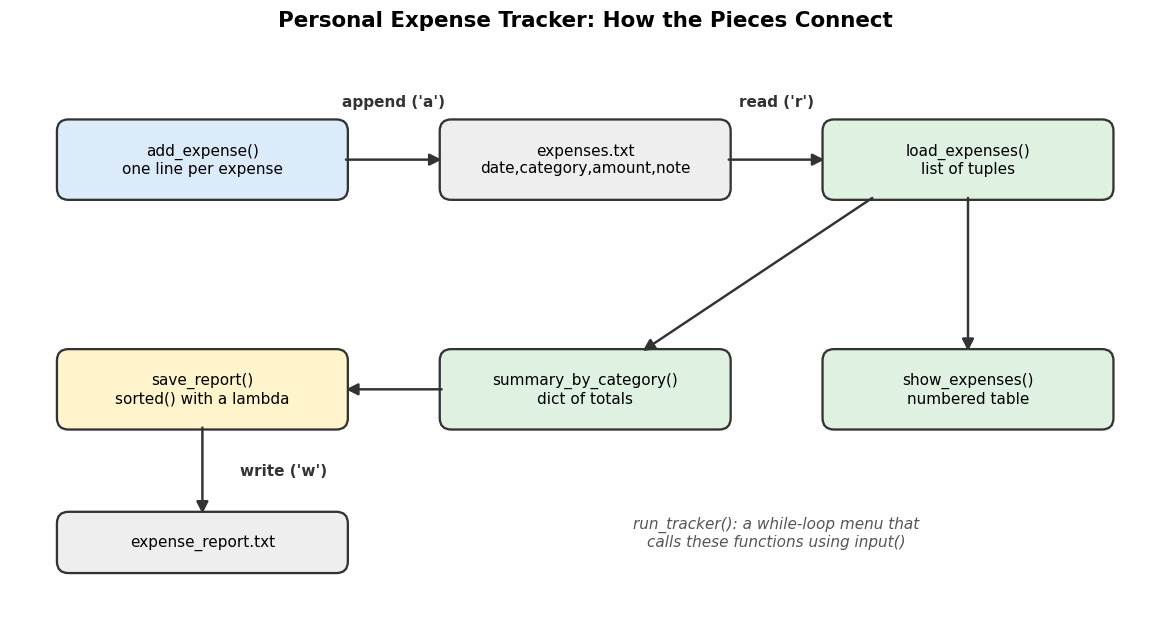

### Step 1: Setup

The file name is stored in a constant, so it can be changed in one place.

In [ ]:
# Step 1: Setup
import os

EXPENSE_FILE = 'expenses.txt'
if os.path.exists(EXPENSE_FILE):
    os.remove(EXPENSE_FILE)          # start fresh for this demo
print('Ready. Expenses will be saved in', EXPENSE_FILE)
# Expected output: Ready. Expenses will be saved in expenses.txt

### Step 2: Save Expenses

Each expense becomes **one line** of the file, with the fields separated by commas: `date,category,amount,note`. Mode `'a'` keeps the earlier expenses.

In [ ]:
# Step 2: Append one expense per line
def add_expense(date, category, amount, note=''):
    """Append one expense to the file as: date,category,amount,note"""
    note = note.replace(',', ' ')          # a comma would break our line format
    with open(EXPENSE_FILE, 'a', encoding='utf-8') as file:
        file.write(f'{date},{category},{amount},{note}\n')

add_expense('2026-11-01', 'Food', 250, 'Lunch with friends')
add_expense('2026-11-02', 'Travel', 100, 'Metro card recharge')
add_expense('2026-11-03', 'Food', 150, 'Groceries')
add_expense('2026-11-05', 'Bills', 600, 'Internet bill')
add_expense('2026-11-06', 'Shopping', 1400, 'Shoes')

with open(EXPENSE_FILE, 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# 2026-11-01,Food,250,Lunch with friends
# 2026-11-02,Travel,100,Metro card recharge
# 2026-11-03,Food,150,Groceries
# 2026-11-05,Bills,600,Internet bill
# 2026-11-06,Shopping,1400,Shoes

### Step 3: Load and Show Expenses

`load_expenses()` reads every line, splits it into fields, converts the amount with `float()`, and returns a **list of tuples**. It returns an empty list if the file does not exist yet.

In [ ]:
# Step 3: Read the file back into a list of tuples
def load_expenses():
    """Return a list of (date, category, amount, note) tuples from the file."""
    expenses = []
    if not os.path.exists(EXPENSE_FILE):
        return expenses
    with open(EXPENSE_FILE, 'r', encoding='utf-8') as file:
        for line in file:
            line = line.strip()
            if line == '':
                continue                       # skip blank lines
            date, category, amount, note = line.split(',')
            expenses.append((date, category, float(amount), note))
    return expenses

def show_expenses(expenses):
    """Print every expense as a numbered table."""
    if not expenses:
        print('No expenses recorded yet')
        return
    for number, (date, category, amount, note) in enumerate(expenses, start=1):
        print(f'{number}. {date}  {category:<9} Rs. {amount:>7.2f}  {note}')

expenses = load_expenses()
print('Loaded', len(expenses), 'expenses')
show_expenses(expenses)
# Expected output:
# Loaded 5 expenses
# 1. 2026-11-01  Food      Rs.  250.00  Lunch with friends
# 2. 2026-11-02  Travel    Rs.  100.00  Metro card recharge
# 3. 2026-11-03  Food      Rs.  150.00  Groceries
# 4. 2026-11-05  Bills     Rs.  600.00  Internet bill
# 5. 2026-11-06  Shopping  Rs. 1400.00  Shoes

### Step 4: Totals per Category

A dictionary collects the total amount for each category.

In [ ]:
# Step 4: Add up the spending in each category
def summary_by_category(expenses):
    """Return a dictionary {category: total amount}."""
    totals = {}
    for date, category, amount, note in expenses:
        totals[category] = totals.get(category, 0) + amount
    return totals

print(summary_by_category(expenses))
# Expected output: {'Food': 400.0, 'Travel': 100.0, 'Bills': 600.0, 'Shopping': 1400.0}

### Step 5: Save a Report

`save_report()` writes a sorted summary (biggest category first, using a `lambda`) into a separate file with mode `'w'`, and returns the grand total.

In [ ]:
# Step 5: Write a summary report to its own file
def save_report(expenses, filename='expense_report.txt'):
    """Write a category summary to a text file and return the grand total."""
    totals = summary_by_category(expenses)
    grand_total = sum(totals.values())
    date, category, amount, note = max(expenses, key=lambda e: e[2])   # biggest single expense
    with open(filename, 'w', encoding='utf-8') as file:
        file.write('EXPENSE REPORT\n')
        file.write('-' * 30 + '\n')
        for cat, total in sorted(totals.items(), key=lambda pair: pair[1], reverse=True):
            percent = total / grand_total * 100
            file.write(f'{cat:<10} Rs. {total:>8.2f}  ({percent:.1f}%)\n')
        file.write('-' * 30 + '\n')
        label = 'TOTAL'
        file.write(f'{label:<10} Rs. {grand_total:>8.2f}\n')
        file.write(f'Highest single expense: {note} (Rs. {amount:.2f})\n')
    return grand_total

total = save_report(expenses)
print('Report saved. Total spent:', total)
with open('expense_report.txt', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# Report saved. Total spent: 2500.0
# EXPENSE REPORT
# ------------------------------
# Shopping   Rs.  1400.00  (56.0%)
# Bills      Rs.   600.00  (24.0%)
# Food       Rs.   400.00  (16.0%)
# Travel     Rs.   100.00  (4.0%)
# ------------------------------
# TOTAL      Rs.  2500.00
# Highest single expense: Shoes (Rs. 1400.00)

### Step 6: The Complete Interactive App

A `while True` menu that uses all the functions above. The amount is checked with `try-except` and `raise` (Section B), so a typo never crashes the program. Add a few expenses, stop the program and run it again: your expenses are still there, because they live in a file.

In [ ]:
# Step 6: The menu-driven expense tracker (uses input)
def run_tracker():
    """Menu-driven expense tracker. The data stays in the file between runs."""
    while True:
        print()
        print('1. Add expense  2. View expenses  3. Summary report  4. Exit')
        choice = input('Choose an option: ')
        if choice == '1':
            date = input('Date (YYYY-MM-DD): ').strip()
            category = input('Category: ').strip().title()
            try:
                amount = float(input('Amount: '))
                if amount <= 0:
                    raise ValueError('the amount must be more than 0')
            except ValueError as e:
                print('  Invalid amount:', e)
                continue
            note = input('Note (optional): ').strip()
            add_expense(date, category, amount, note)
            print('  Saved!')
        elif choice == '2':
            show_expenses(load_expenses())
        elif choice == '3':
            all_expenses = load_expenses()
            if not all_expenses:
                print('  Nothing to report yet')
                continue
            save_report(all_expenses)
            with open('expense_report.txt', 'r', encoding='utf-8') as file:
                print(file.read(), end='')
        elif choice == '4':
            print('Goodbye! Your expenses are saved in', EXPENSE_FILE)
            break
        else:
            print('  Invalid option, choose 1 to 4')

run_tracker()
# Example run:
#
# 1. Add expense  2. View expenses  3. Summary report  4. Exit
# Choose an option: 1
# Date (YYYY-MM-DD): 2026-11-23
# Category: food
# Amount: 45
# Note (optional): Tea
#   Saved!
#
# 1. Add expense  2. View expenses  3. Summary report  4. Exit
# Choose an option: 2
# 1. 2026-11-01  Food      Rs.  250.00  Lunch with friends
# 2. 2026-11-02  Travel    Rs.  100.00  Metro card recharge
# 3. 2026-11-03  Food      Rs.  150.00  Groceries
# 4. 2026-11-05  Bills     Rs.  600.00  Internet bill
# 5. 2026-11-06  Shopping  Rs. 1400.00  Shoes
# 6. 2026-11-23  Food      Rs.   45.00  Tea
#
# 1. Add expense  2. View expenses  3. Summary report  4. Exit
# Choose an option: 4
# Goodbye! Your expenses are saved in expenses.txt

### Make It Your Own

1. Add a menu option that shows only the expenses of one category
2. Add `delete_expense(number)`: read all lines, skip one, write the rest back with `'w'`
3. Make `load_expenses()` skip damaged lines with `try-except` and report them (like Project 2)
4. Show the total spent in each month (hint: `date[:7]` gives `'2026-11'`)
5. Warn the user when a single expense is above Rs. 1000

---
# Part 25: Project 2 - Safe Marks Processor

Real data is messy. In this project, a teacher's marks file has missing fields, words instead of numbers, and impossible marks. Our program must:
1. Read the file line by line, and ask again if the file name is wrong
2. Check every line and raise **custom exceptions** for bad lines
3. **Never stop** because of one bad line: log it to `errors.log` and continue
4. Write the valid records, with grades, to `results.txt`
5. Print a class summary

**Where each concept is used**

| Topic | Concepts | Used in |
|---|---|---|
| Basic Syntax | f-strings, `input()`, `int()` | messages, the file-name prompt |
| Data Structures | list of tuples, dictionary | valid records, grade counts |
| Control Flow | `for`, `while True`, `if-elif`, `continue`, `break` | the processing and input loops |
| Functions | parameters, defaults, `return`, `lambda` | `parse_record()`, `get_grade()`, `print_summary()` |
| Files (Section A) | `with`, modes `'r'` and `'w'`, `split()` | reading the raw file, writing results and the log |
| Exceptions (Section B) | custom exceptions, `raise`, `try-except-else`, `FileNotFoundError`, propagation | every step |

**Run every step in order.**

**Diagram: How the marks processor works**

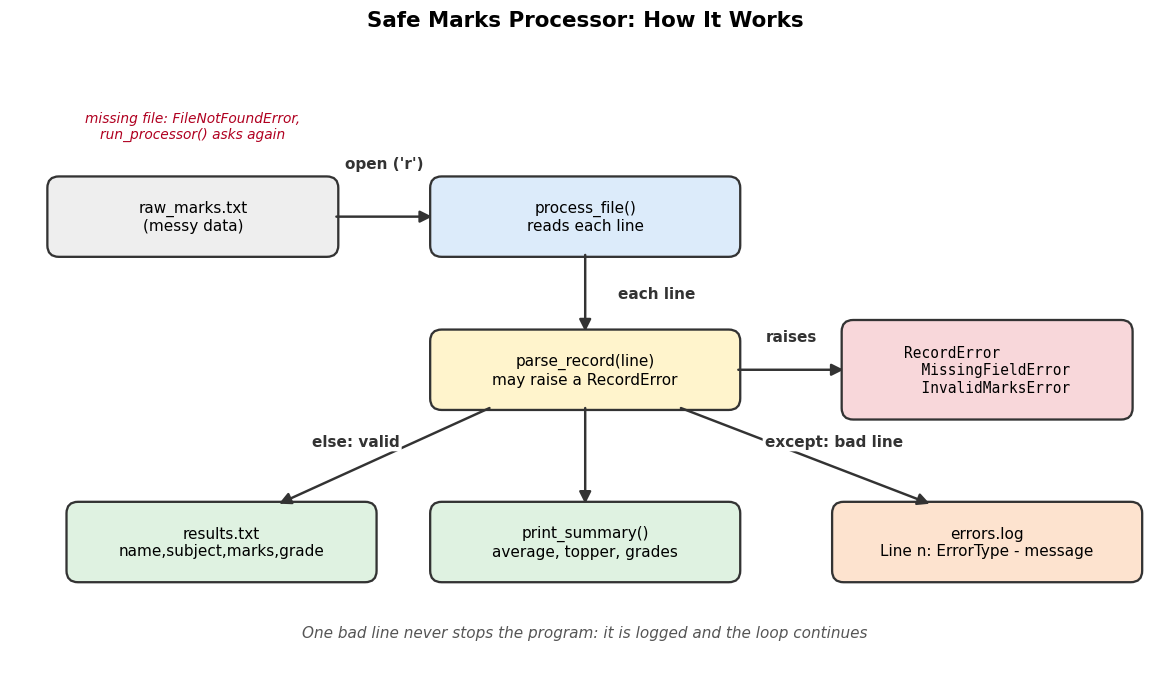

### Step 1: Create the Messy Input File

Each line should be `name,subject,marks`, but some lines are broken.

In [ ]:
# Step 1: A marks file with mistakes in it
raw_lines = ['Asha,Maths,91', 'Ravi,Maths,67', 'Meena,Maths,abc', 'John,Maths',
             'Priya,Maths,105', 'Kiran,Maths,48', ',Maths,72', 'Sara,Maths,84']
with open('raw_marks.txt', 'w', encoding='utf-8') as file:
    for line in raw_lines:
        file.write(line + '\n')

with open('raw_marks.txt', 'r', encoding='utf-8') as file:
    for number, line in enumerate(file, start=1):
        print(number, line.strip())
# Expected output:
# 1 Asha,Maths,91
# 2 Ravi,Maths,67
# 3 Meena,Maths,abc
# 4 John,Maths
# 5 Priya,Maths,105
# 6 Kiran,Maths,48
# 7 ,Maths,72
# 8 Sara,Maths,84

### Step 2: Custom Exceptions

A small family: `RecordError` is the parent, with two specific children. Catching `RecordError` catches both.

In [ ]:
# Step 2: Our own exception types
class RecordError(Exception):
    pass          # parent: any problem with one line of the file

class MissingFieldError(RecordError):
    pass          # a field is missing or empty

class InvalidMarksError(RecordError):
    pass          # marks are not a number, or not between 0 and 100

try:
    raise InvalidMarksError('test')
except RecordError as e:
    print('Caught through the parent class:', type(e).__name__)
# Expected output: Caught through the parent class: InvalidMarksError

### Step 3: Check One Line

`parse_record()` either returns a clean `(name, subject, marks)` tuple or **raises** the right custom exception. It does not print anything; the caller decides what to do.

In [ ]:
# Step 3: Turn one line into a record, or raise a RecordError
def parse_record(line):
    """Return (name, subject, marks) from 'name,subject,marks', or raise a RecordError."""
    parts = line.strip().split(',')
    if len(parts) != 3:
        raise MissingFieldError(f'expected 3 fields, got {len(parts)}')
    name, subject, marks_text = parts
    if name.strip() == '':
        raise MissingFieldError('name is empty')
    try:
        marks = int(marks_text)
    except ValueError:
        raise InvalidMarksError(f'marks must be a number, got {repr(marks_text)}')
    if marks < 0 or marks > 100:
        raise InvalidMarksError(f'marks must be between 0 and 100, got {marks}')
    return name.strip(), subject.strip(), marks

for line in ['Asha,Maths,91', 'John,Maths', 'Meena,Maths,abc', 'Priya,Maths,105']:
    try:
        print('OK   ', parse_record(line))
    except RecordError as e:
        print('ERROR', type(e).__name__, '-', e)
# Expected output:
# OK    ('Asha', 'Maths', 91)
# ERROR MissingFieldError - expected 3 fields, got 2
# ERROR InvalidMarksError - marks must be a number, got 'abc'
# ERROR InvalidMarksError - marks must be between 0 and 100, got 105

### Step 4: Grades

In [ ]:
# Step 4: Marks to grade
def get_grade(marks):
    """Return the grade letter for valid marks (0-100)."""
    if marks >= 90:
        return 'A'
    elif marks >= 75:
        return 'B'
    elif marks >= 50:
        return 'C'
    return 'F'

print(get_grade(91), get_grade(84), get_grade(67), get_grade(48))
# Expected output: A B C F

### Step 5: Process the Whole File

- `except RecordError` logs each bad line to `errors.log`, and the loop **continues**.
- `else` runs only for good lines: it writes the result.
- If the input file is missing, `open()` raises `FileNotFoundError`. It is **not** caught here; it travels up to the caller (Part 16).

In [ ]:
# Step 5: Read every line, keep the good ones, log the bad ones
def process_file(input_file, results_file='results.txt', error_file='errors.log'):
    """Write valid records to results_file and problems to error_file. Return the valid records."""
    records = []
    with open(input_file, 'r', encoding='utf-8') as source:      # may raise FileNotFoundError
        lines = source.readlines()
    with open(results_file, 'w', encoding='utf-8') as results, open(error_file, 'w', encoding='utf-8') as errors:
        for number, line in enumerate(lines, start=1):
            if line.strip() == '':
                continue                                       # ignore blank lines
            try:
                name, subject, marks = parse_record(line)
            except RecordError as e:
                errors.write(f'Line {number}: {type(e).__name__} - {e}\n')
            else:
                grade = get_grade(marks)
                results.write(f'{name},{subject},{marks},{grade}\n')
                records.append((name, subject, marks, grade))
    return records

records = process_file('raw_marks.txt')
print('Valid records:', len(records))
print()
print('results.txt:')
with open('results.txt', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
print()
print('errors.log:')
with open('errors.log', 'r', encoding='utf-8') as file:
    print(file.read(), end='')
# Expected output:
# Valid records: 4
#
# results.txt:
# Asha,Maths,91,A
# Ravi,Maths,67,C
# Kiran,Maths,48,F
# Sara,Maths,84,B
#
# errors.log:
# Line 3: InvalidMarksError - marks must be a number, got 'abc'
# Line 4: MissingFieldError - expected 3 fields, got 2
# Line 5: InvalidMarksError - marks must be between 0 and 100, got 105
# Line 7: MissingFieldError - name is empty

### Step 6: Class Summary

In [ ]:
# Step 6: Statistics for the valid records
def print_summary(records):
    """Print the class average, the topper and the grade counts."""
    if not records:
        print('No valid records to summarise')
        return
    total = 0
    grade_counts = {}
    for name, subject, marks, grade in records:
        total += marks
        grade_counts[grade] = grade_counts.get(grade, 0) + 1
    topper = max(records, key=lambda r: r[2])
    print('Students processed:', len(records))
    print('Class average:', total / len(records))
    print('Topper:', topper[0], 'with', topper[2])
    print('Grades:', dict(sorted(grade_counts.items())))

print_summary(records)
# Expected output:
# Students processed: 4
# Class average: 72.5
# Topper: Asha with 91
# Grades: {'A': 1, 'B': 1, 'C': 1, 'F': 1}

### Step 7: The Complete Program

The user types a file name. A wrong name raises `FileNotFoundError` inside `process_file()`, which is caught **here**, and the program asks again. Press Enter to use `raw_marks.txt`.

In [ ]:
# Step 7: The full processor (uses input)
def run_processor():
    """Ask for a marks file until one can be processed, then show the summary."""
    while True:
        filename = input('Marks file to process (Enter for raw_marks.txt): ').strip()
        if filename == '':
            filename = 'raw_marks.txt'
        try:
            records = process_file(filename)
        except FileNotFoundError:
            print(f'  {filename} was not found, please try again')
        else:
            break                         # success: leave the loop
    print_summary(records)
    with open('errors.log', 'r', encoding='utf-8') as file:
        problems = len(file.readlines())
    print('Problems found:', problems, '(see errors.log)')
    print('Results saved in results.txt')

run_processor()
# Example run:
# Marks file to process (Enter for raw_marks.txt): class10.txt
#   class10.txt was not found, please try again
# Marks file to process (Enter for raw_marks.txt):
# Students processed: 4
# Class average: 72.5
# Topper: Asha with 91
# Grades: {'A': 1, 'B': 1, 'C': 1, 'F': 1}
# Problems found: 4 (see errors.log)
# Results saved in results.txt

### Make It Your Own

1. Add a `DuplicateStudentError` for a name that appears twice
2. Accept marks with decimals, such as `72.5`
3. Process several files in one run and combine the summaries
4. Add the date and time of each run to the top of `errors.log`
5. Let the user choose the pass mark, using `get_number()` from Part 20

---
### Well done!

You have completed the File Handling and Exception Handling lab. Your programs can now remember data between runs, survive bad input, missing files and messy data, and explain clearly what went wrong.